In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
# --- Paths (adjust if needed) ---
RESULTS_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/"
    "calc_files/MI/testing_permutations/mi_analysis_results_MI_label_entropy_all_genes_parallel/discret_round_d1"
)

OUTPUT_BASE_DIR = RESULTS_DIR.parent  # .../mi_analysis_results... (parent of discret_round_d1)
SEL_DIR = OUTPUT_BASE_DIR / "selected_gene_sets"

DATASETS = ["treutlein", "weinreb", "junker"]
PERMS = [50, 100, 200, 500, 1000]
REF_NPERM = 1000

RESULTS_DIR, SEL_DIR


(PosixPath('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/testing_permutations/mi_analysis_results_MI_label_entropy_all_genes_parallel/discret_round_d1'),
 PosixPath('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/testing_permutations/mi_analysis_results_MI_label_entropy_all_genes_parallel/selected_gene_sets'))

In [4]:
PAT = re.compile(
    r"MI_label_entropy_(?P<dataset>[^_]+)_(?P<nperm>\d+)_permutations_(?P<tag>discret_round_d1).*_SUBSET_.*\.csv$"
)

rows = []
for p in RESULTS_DIR.glob("MI_label_entropy_*_SUBSET_*.csv"):
    m = PAT.match(p.name)
    if not m:
        continue
    rows.append((m.group("dataset"), int(m.group("nperm")), m.group("tag"), p))

inv = pd.DataFrame(rows, columns=["dataset", "n_perm", "tag", "path"]).sort_values(["dataset","n_perm"])
inv = inv[inv["dataset"].isin(DATASETS) & inv["n_perm"].isin(PERMS)].reset_index(drop=True)

inv


,dataset,n_perm,tag,path
0,junker,50,discret_round_d1,/fast/AG_Metzger/philipp/python_files/gene_sig...
1,junker,100,discret_round_d1,/fast/AG_Metzger/philipp/python_files/gene_sig...
2,junker,200,discret_round_d1,/fast/AG_Metzger/philipp/python_files/gene_sig...
3,junker,500,discret_round_d1,/fast/AG_Metzger/philipp/python_files/gene_sig...
4,junker,1000,discret_round_d1,/fast/AG_Metzger/philipp/python_files/gene_sig...
5,treutlein,50,discret_round_d1,/fast/AG_Metzger/philipp/python_files/gene_sig...
6,treutlein,100,discret_round_d1,/fast/AG_Metzger/philipp/python_files/gene_sig...
7,treutlein,200,discret_round_d1,/fast/AG_Metzger/philipp/python_files/gene_sig...
8,treutlein,500,discret_round_d1,/fast/AG_Metzger/philipp/python_files/gene_sig...
9,treutlein,1000,discret_round_d1,/fast/AG_Metzger/philipp/python_files/gene_sig...


In [5]:
def load_set_labels(dataset: str) -> pd.DataFrame:
    hits = sorted(SEL_DIR.glob(f"selected_{dataset}_discret_round_d1_top*_rand*_seed*_ref*.tsv"))
    if not hits:
        raise FileNotFoundError(f"No selection file found for {dataset} in {SEL_DIR}")
    sel = pd.read_csv(hits[0], sep="\t")
    sel["set"] = sel["set"].map({"top":"top200", "random":"random200"}).fillna(sel["set"])
    return sel[["gene","set"]]

labels = {ds: load_set_labels(ds) for ds in DATASETS}
for ds in DATASETS:
    print(ds, labels[ds]["set"].value_counts().to_dict())


treutlein {'top200': 200, 'random200': 200}
weinreb {'top200': 200, 'random200': 200}
junker {'top200': 200, 'random200': 200}


In [6]:
def load_one(path: Path, dataset: str, n_perm: int) -> pd.DataFrame:
    df = pd.read_csv(path)
    need = {"gene","true_mi","95_perm_mi"}
    missing = need.difference(df.columns)
    if missing:
        raise ValueError(f"Missing columns {missing} in {path}")
    df = df.copy()
    df["dataset"] = dataset
    df["n_perm"] = n_perm
    df["sig"] = df["true_mi"] > df["95_perm_mi"]
    df["margin"] = df["true_mi"] - df["95_perm_mi"]
    return df

dfs = []
for ds in DATASETS:
    for n in PERMS:
        sub = inv[(inv["dataset"]==ds) & (inv["n_perm"]==n)]
        if sub.empty:
            print(f"[WARN] missing: {ds} n={n}")
            continue
        # if multiple matches, take first (can change logic if needed)
        p = sub.iloc[0]["path"]
        dfs.append(load_one(p, ds, n))

all_df = pd.concat(dfs, ignore_index=True)

# attach set labels
lab = pd.concat([labels[ds].assign(dataset=ds) for ds in DATASETS], ignore_index=True)
all_df = all_df.merge(lab, on=["dataset","gene"], how="left")

all_df.head()


,gene,n_states,true_mi,mean_perm_mi,95_perm_mi,std_perm_mi,normalized_MI_label_entropy,dataset,n_perm,sig,margin,set
0,MT-ND3,56,2.424044,2.015242,2.022438,0.005517,0.255378,treutlein,50,True,0.401605,top200
1,MT-ATP6,54,2.262028,1.946857,1.952019,0.003480,0.238309,treutlein,50,True,0.310009,top200
2,eGFP,49,2.247599,1.558151,1.569267,0.006299,0.236789,treutlein,50,True,0.678332,top200
3,MT-CO3,58,2.206211,1.868094,1.874788,0.004166,0.232429,treutlein,50,True,0.331422,top200
4,VIM,58,2.188112,2.038268,2.050442,0.005822,0.230522,treutlein,50,True,0.137669,top200


In [7]:
def jaccard(a, b):
    a = set(a); b = set(b)
    return np.nan if len(a|b)==0 else len(a&b)/len(a|b)

summary_rows = []

for ds in DATASETS:
    # choose reference nperm (1000 if exists else max available)
    avail = sorted(all_df.loc[all_df["dataset"]==ds, "n_perm"].unique().tolist())
    ref_n = REF_NPERM if REF_NPERM in avail else avail[-1]

    ref = all_df[(all_df["dataset"]==ds) & (all_df["n_perm"]==ref_n)][["gene","sig","margin","set"]].set_index("gene")
    ref = ref.rename(columns={"sig":"sig_ref","margin":"margin_ref"})

    for n in PERMS:
        cur = all_df[(all_df["dataset"]==ds) & (all_df["n_perm"]==n)][["gene","sig","margin","set"]].set_index("gene")
        if cur.empty:
            continue
        cur = cur.rename(columns={"sig":"sig_n","margin":"margin_n"})

        m = ref.join(cur, how="inner", lsuffix="_r", rsuffix="_c")
        m["flip"] = m["sig_n"] != m["sig_ref"]

        for set_name in ["all", "top200", "random200"]:
            if set_name == "all":
                sub = m
            else:
                sub = m[m["set_r"] == set_name]  # set column is duplicated via join; use ref side
            if sub.empty:
                continue

            concord = float((sub["sig_n"] == sub["sig_ref"]).mean())
            flips = int(sub["flip"].sum())

            S_n = sub.index[sub["sig_n"]].tolist()
            S_r = sub.index[sub["sig_ref"]].tolist()
            jac = float(jaccard(S_n, S_r))

            summary_rows.append({
                "dataset": ds,
                "n_perm": n,
                "ref_perm": ref_n,
                "set": set_name,
                "n_genes": int(sub.shape[0]),
                "concordance_vs_ref": concord,
                "n_flips_vs_ref": flips,
                "jaccard_sigset_vs_ref": jac,
                "median_margin_n": float(np.median(sub["margin_n"])),
                "median_margin_ref": float(np.median(sub["margin_ref"])),
            })

summary = pd.DataFrame(summary_rows).sort_values(["dataset","set","n_perm"])
summary


,dataset,n_perm,ref_perm,set,n_genes,concordance_vs_ref,n_flips_vs_ref,jaccard_sigset_vs_ref,median_margin_n,median_margin_ref
30,junker,50,1000,all,400,0.9600,16,0.921951,-0.000054,-0.000329
33,junker,100,1000,all,400,0.9750,10,0.950495,-0.000107,-0.000329
36,junker,200,1000,all,400,0.9875,5,0.974747,-0.000125,-0.000329
39,junker,500,1000,all,400,0.9950,2,0.989796,-0.000298,-0.000329
42,junker,1000,1000,all,400,1.0000,0,1.000000,-0.000329,-0.000329
32,junker,50,1000,random200,200,0.9650,7,0.611111,-0.002961,-0.003179
35,junker,100,1000,random200,200,0.9800,4,0.733333,-0.003197,-0.003179
38,junker,200,1000,random200,200,0.9850,3,0.800000,-0.003089,-0.003179
41,junker,500,1000,random200,200,1.0000,0,1.000000,-0.003272,-0.003179
44,junker,1000,1000,random200,200,1.0000,0,1.000000,-0.003179,-0.003179


In [8]:
summary[summary["set"]=="top200"].pivot(index="n_perm", columns="dataset", values="concordance_vs_ref")


dataset,junker,treutlein,weinreb
n_perm,,,
50,0.955,1.0,1.0
100,0.970,1.0,1.0
200,0.990,1.0,1.0
500,0.990,1.0,1.0
1000,1.000,1.0,1.0


In [9]:
summary[summary["set"]=="top200"].pivot(index="n_perm", columns="dataset", values="n_flips_vs_ref")


dataset,junker,treutlein,weinreb
n_perm,,,
50,9,0,0
100,6,0,0
200,2,0,0
500,2,0,0
1000,0,0,0


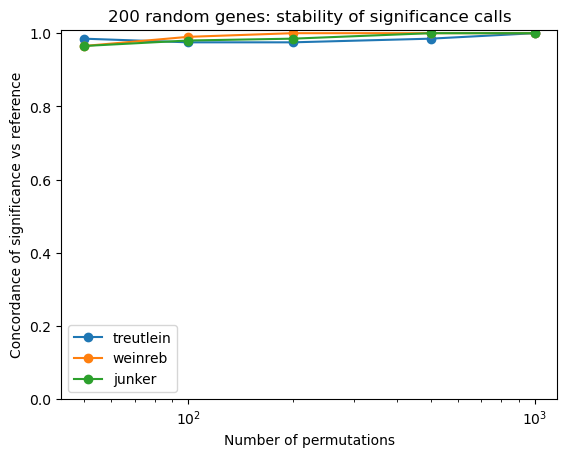

In [14]:
top = summary[summary["set"]=="random200"].copy()

plt.figure()
for ds in DATASETS:
    sub = top[top["dataset"]==ds].sort_values("n_perm")
    plt.plot(sub["n_perm"], sub["concordance_vs_ref"], marker="o", label=ds)
plt.xscale("log")
plt.ylim(0, 1.01)
plt.xlabel("Number of permutations")
plt.ylabel("Concordance of significance vs reference")
plt.title("200 random genes: stability of significance calls")
plt.savefig("200random_stability_significant_cells.pdf", bbox_inches = "tight")
plt.legend()
plt.show()


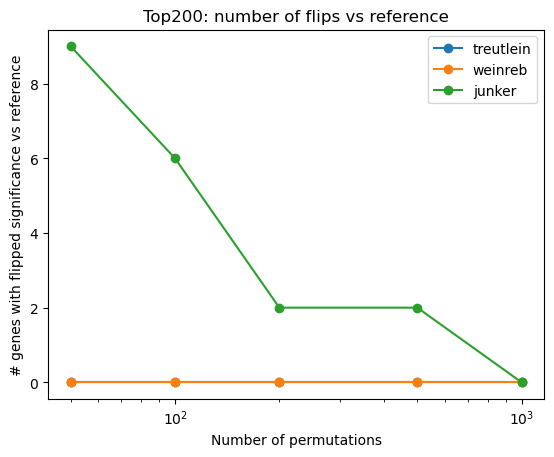

In [10]:
plt.figure()
for ds in DATASETS:
    sub = top[top["dataset"]==ds].sort_values("n_perm")
    plt.plot(sub["n_perm"], sub["n_flips_vs_ref"], marker="o", label=ds)
plt.xscale("log")
plt.xlabel("Number of permutations")
plt.ylabel("# genes with flipped significance vs reference")
plt.title("Top200: number of flips vs reference")
plt.legend()
plt.show()


In [11]:
def flipped_genes(ds: str, n: int, ref_n: int = REF_NPERM) -> pd.DataFrame:
    avail = sorted(all_df.loc[all_df["dataset"]==ds, "n_perm"].unique().tolist())
    ref_n = ref_n if ref_n in avail else avail[-1]

    ref = all_df[(all_df["dataset"]==ds) & (all_df["n_perm"]==ref_n)][["gene","sig","margin","set"]].set_index("gene")
    ref = ref.rename(columns={"sig":"sig_ref","margin":"margin_ref"})

    cur = all_df[(all_df["dataset"]==ds) & (all_df["n_perm"]==n)][["gene","sig","margin","set"]].set_index("gene")
    cur = cur.rename(columns={"sig":"sig_n","margin":"margin_n"})

    m = ref.join(cur, how="inner", lsuffix="_r", rsuffix="_c")
    m["flip"] = m["sig_n"] != m["sig_ref"]
    out = m[m["flip"]].copy().reset_index()
    out["dataset"] = ds
    out["n_perm"] = n
    out["ref_perm"] = ref_n
    return out.sort_values("margin_ref")

# Example: flips in top200 at 50 perms
flips_50 = []
for ds in DATASETS:
    f = flipped_genes(ds, 50, REF_NPERM)
    f = f[f["set_r"]=="top200"]
    flips_50.append(f)
flips_50 = pd.concat(flips_50, ignore_index=True)
flips_50


,gene,sig_ref,margin_ref,set_r,sig_n,margin_n,set_c,flip,dataset,n_perm,ref_perm
0,ppdpfb,False,-0.004550,top200,True,0.000189,top200,True,junker,50,1000
1,mt-nd4,False,-0.001257,top200,True,0.002268,top200,True,junker,50,1000
2,COX5B,False,-0.000642,top200,True,0.002561,top200,True,junker,50,1000
3,krtt1c19e,False,-0.000635,top200,True,0.003614,top200,True,junker,50,1000
4,mt-nd2,False,-0.000188,top200,True,0.004667,top200,True,junker,50,1000
5,krt91,True,0.000007,top200,False,-0.003225,top200,True,junker,50,1000
6,oaz1a,True,0.000416,top200,False,-0.000086,top200,True,junker,50,1000
7,cox7a2a,True,0.001672,top200,False,-0.002579,top200,True,junker,50,1000
8,mt-nd1,True,0.001987,top200,False,-0.000203,top200,True,junker,50,1000


In [ ]:
ds = "weinreb"
f = flipped_genes(ds, 50, REF_NPERM)
ref_n = REF_NPERM if REF_NPERM in all_df.loc[all_df["dataset"]==ds,"n_perm"].unique() else max(all_df.loc[all_df["dataset"]==ds,"n_perm"])
ref = all_df[(all_df["dataset"]==ds) & (all_df["n_perm"]==ref_n)].merge(labels[ds], on="gene", how="left")
ref["flip_at_50"] = ref["gene"].isin(f["gene"].tolist())

plt.figure()
plt.hist(ref.loc[(ref["set"]=="top200") & (~ref["flip_at_50"]), "margin"], bins=30, alpha=0.7, label="top200 stable")
plt.hist(ref.loc[(ref["set"]=="top200") & (ref["flip_at_50"]), "margin"], bins=30, alpha=0.7, label="top200 flips")
plt.xlabel("margin (true_mi - perm95)")
plt.ylabel("count")
plt.title(f"{ds}: margin distribution (ref perm)")
plt.legend()
plt.show()
